# FIFA World Cup 2026 — linear regression for Objective 2

This notebook evaluates the two models in the project brief. The fitting code is in `scripts/analyse_linreg.py`. It follows the Week 9 practical: a linear regression against a mean baseline, then collinearity, z-score rescaling, a log-style transform, and Yeo-Johnson.

- **2.1** predicts goal difference for a match. 104 rows.
- **2.2** predicts goals scored by one team in one match. 208 rows.

Each table has one key, eight explanatory variables, and one response. Every explanatory variable is known before kickoff. The two tables do not share an explanatory variable.

A change is kept only when five-fold cross-validation error falls. The R-squared of a model fitted on every row is shown as well, and it is not the test result.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts" / "analyse_linreg.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

import analyse_linreg as al

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.max_colwidth", 80)
print("Project:", ROOT)

Project: C:\Users\kaush\OneDrive\Desktop\Assignment_FoundationDS\Assignment3_obj2


## Data check

The brief asks for 104 matches, 208 team-matches, and exactly eight explanatory variables in each model. The check below confirms those counts and that the explanatory names do not overlap.

In [2]:
match = pd.read_csv(ROOT / "data" / "linreg_2_1.csv")
team = pd.read_csv(ROOT / "data" / "linreg_2_2.csv")

x1 = [c for c in match.columns if c not in ("match_id", "goal_diff")]
x2 = [c for c in team.columns if c not in ("team_match_id", "goals")]

print("2.1 rows, columns:", match.shape)
print("2.1 explanatory variables:", x1)
print("2.2 rows, columns:", team.shape)
print("2.2 explanatory variables:", x2)
print("Shared explanatory names:", sorted(set(x1) & set(x2)))
print("Empty cells:", int(match.isna().sum().sum() + team.isna().sum().sum()))
match.head(3)

2.1 rows, columns: (104, 10)
2.1 explanatory variables: ['fifa_points_diff', 'qual_gd_per_game_diff', 'market_value_avg_diff', 'age_avg_diff', 'host', 'rest_days_diff', 'wc_gd_so_far', 'wc_experience_diff']
2.2 rows, columns: (208, 10)
2.2 explanatory variables: ['qual_gf_per_game', 'opp_qual_ga_per_game', 'wc_goals_so_far', 'opp_wc_ga_so_far', 'foreigners_pct', 'opp_foreigners_pct', 'squad_size', 'opp_squad_size']
Shared explanatory names: []
Empty cells: 0


,match_id,fifa_points_diff,qual_gd_per_game_diff,market_value_avg_diff,age_avg_diff,host,rest_days_diff,wc_gd_so_far,wc_experience_diff,goal_diff
0,M001_Mexico_SouthAfrica,259.1000,0.5667,6.3400,-1.3000,1,0,0.0000,14,2
1,M002_SouthKorea_Czechia,85.8900,0.0500,-2.4300,2.3000,0,0,0.0000,10,1
2,M003_Canada_BosniaandHerzegovina,172.2600,0.7500,-0.9700,0.7000,1,0,0.0000,1,0


## Descriptive statistics

Count, mean, standard deviation, and the quartiles for every explanatory variable and the response. The match key is left out. These numbers describe the tables. They are not the test of the models.

In [3]:
def summary(frame, columns):
    stats = frame[columns].describe().T
    return stats[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(4)

print("2.1 goal difference")
display(summary(match, x1 + ["goal_diff"]))
print("2.2 goals scored")
display(summary(team, x2 + ["goals"]))

2.1 goal difference


,count,mean,std,min,25%,50%,75%,max
fifa_points_diff,104.0000,55.1877,231.4899,-489.5300,-127.7475,67.7650,232.2625,506.1600
qual_gd_per_game_diff,104.0000,0.1146,1.6568,-4.5000,-0.8083,0.0750,1.0500,4.2083
market_value_avg_diff,104.0000,5.6329,23.2073,-57.4700,-5.6150,4.7200,18.8400,62.8740
age_avg_diff,104.0000,-0.2942,1.6525,-4.9000,-1.3250,-0.3000,0.8000,3.9000
host,104.0000,0.0673,0.3488,-1.0000,0.0000,0.0000,0.0000,1.0000
rest_days_diff,104.0000,0.0192,0.8588,-2.0000,-1.0000,0.0000,1.0000,4.0000
wc_gd_so_far,104.0000,0.2421,1.8506,-6.0000,0.0000,0.0000,1.0000,5.0000
wc_experience_diff,104.0000,2.6923,9.0114,-19.0000,-3.0000,2.5000,10.0000,21.0000
goal_diff,104.0000,0.4808,2.0240,-4.0000,-1.0000,0.0000,2.0000,6.0000


2.2 goals scored


,count,mean,std,min,25%,50%,75%,max
qual_gf_per_game,208.0000,2.2795,0.9665,0.6667,1.6000,2.2000,2.7500,5.8000
opp_qual_ga_per_game,208.0000,0.6624,0.4420,0.0000,0.3333,0.6000,0.8750,2.4000
wc_goals_so_far,208.0000,1.3294,1.2134,0.0000,0.0000,1.0000,2.0000,7.0000
opp_wc_ga_so_far,208.0000,0.9766,1.1010,0.0000,0.0000,1.0000,1.2708,7.0000
foreigners_pct,208.0000,69.7630,27.3748,0.0000,49.3750,80.0000,92.0750,100.0000
opp_foreigners_pct,208.0000,69.7630,27.3748,0.0000,49.3750,80.0000,92.0750,100.0000
squad_size,208.0000,26.5000,3.5766,22.0000,24.0000,26.0000,28.0000,43.0000
opp_squad_size,208.0000,26.5000,3.5766,22.0000,24.0000,26.0000,28.0000,43.0000
goals,208.0000,1.4808,1.3934,0.0000,0.0000,1.0000,2.0000,7.0000


## Correlations

Pearson correlation among the explanatory variables and with the response. The second table ranks each explanatory variable by how strongly it lines up with the response. The third table lists every explanatory pair whose absolute correlation is 0.75 or more. That is the collinearity rule used when the models are fitted. A pair below 0.75 is left in.

In [4]:
def correlation_matrix(frame, x_columns, y_column):
    return frame[x_columns + [y_column]].corr().round(3)

def link_to_response(frame, x_columns, y_column):
    links = frame[x_columns].corrwith(frame[y_column]).rename("corr_with_response").to_frame()
    links["abs_corr"] = links["corr_with_response"].abs()
    return links.sort_values("abs_corr", ascending=False).round(3)

def strong_pairs(frame, x_columns, limit=0.75):
    corr = frame[x_columns].corr()
    rows = []
    for index, left in enumerate(x_columns):
        for right in x_columns[index + 1:]:
            value = float(corr.loc[left, right])
            if abs(value) >= limit:
                rows.append({"left": left, "right": right, "correlation": round(value, 3)})
    columns = ["left", "right", "correlation"]
    if not rows:
        return pd.DataFrame(columns=columns)
    return pd.DataFrame(rows).sort_values("correlation", key=lambda series: series.abs(), ascending=False)

print("2.1 correlation matrix")
display(correlation_matrix(match, x1, "goal_diff"))
print("2.1 correlation with goal difference")
display(link_to_response(match, x1, "goal_diff"))
print("2.1 explanatory pairs at 0.75 or above")
display(strong_pairs(match, x1))

print("2.2 correlation matrix")
display(correlation_matrix(team, x2, "goals"))
print("2.2 correlation with goals")
display(link_to_response(team, x2, "goals"))
print("2.2 explanatory pairs at 0.75 or above")
display(strong_pairs(team, x2))

2.1 correlation matrix


,fifa_points_diff,qual_gd_per_game_diff,market_value_avg_diff,age_avg_diff,host,rest_days_diff,wc_gd_so_far,wc_experience_diff,goal_diff
fifa_points_diff,1.0000,0.2310,0.7660,-0.2730,0.0990,0.0960,0.4710,0.7910,0.6470
qual_gd_per_game_diff,0.2310,1.0000,0.3730,-0.1290,0.0330,-0.0010,0.1740,0.0700,0.2920
market_value_avg_diff,0.7660,0.3730,1.0000,-0.2710,-0.1040,0.1250,0.4480,0.6920,0.5650
age_avg_diff,-0.2730,-0.1290,-0.2710,1.0000,-0.3830,-0.0550,-0.2040,-0.2800,-0.1650
host,0.0990,0.0330,-0.1040,-0.3830,1.0000,-0.0040,0.1880,0.1430,0.1600
rest_days_diff,0.0960,-0.0010,0.1250,-0.0550,-0.0040,1.0000,0.1250,0.1220,0.1060
wc_gd_so_far,0.4710,0.1740,0.4480,-0.2040,0.1880,0.1250,1.0000,0.4620,0.3180
wc_experience_diff,0.7910,0.0700,0.6920,-0.2800,0.1430,0.1220,0.4620,1.0000,0.5460
goal_diff,0.6470,0.2920,0.5650,-0.1650,0.1600,0.1060,0.3180,0.5460,1.0000


2.1 correlation with goal difference


,corr_with_response,abs_corr
fifa_points_diff,0.6470,0.6470
market_value_avg_diff,0.5650,0.5650
wc_experience_diff,0.5460,0.5460
wc_gd_so_far,0.3180,0.3180
qual_gd_per_game_diff,0.2920,0.2920
age_avg_diff,-0.1650,0.1650
host,0.1600,0.1600
rest_days_diff,0.1060,0.1060


2.1 explanatory pairs at 0.75 or above


...

,qual_gf_per_game,opp_qual_ga_per_game,wc_goals_so_far,opp_wc_ga_so_far,foreigners_pct,opp_foreigners_pct,squad_size,opp_squad_size,goals
qual_gf_per_game,1.0000,-0.0200,0.2390,0.0020,0.0080,-0.0140,-0.0430,-0.0950,0.2470
opp_qual_ga_per_game,-0.0200,1.0000,-0.0880,0.0320,0.0180,-0.1020,-0.0430,0.0930,0.1120
wc_goals_so_far,0.2390,-0.0880,1.0000,0.1660,-0.0350,0.1170,0.2350,-0.0970,0.0580
opp_wc_ga_so_far,0.0020,0.0320,0.1660,1.0000,0.0870,0.0110,-0.0880,-0.0460,0.1480
foreigners_pct,0.0080,0.0180,-0.0350,0.0870,1.0000,-0.1530,-0.1490,0.0230,-0.0220
opp_foreigners_pct,-0.0140,-0.1020,0.1170,0.0110,-0.1530,1.0000,0.0230,-0.1490,-0.0450
squad_size,-0.0430,-0.0430,0.2350,-0.0880,-0.1490,0.0230,1.0000,-0.0920,0.1430
opp_squad_size,-0.0950,0.0930,-0.0970,-0.0460,0.0230,-0.1490,-0.0920,1.0000,-0.0470
goals,0.2470,0.1120,0.0580,0.1480,-0.0220,-0.0450,0.1430,-0.0470,1.0000


2.2 correlation with goals


,corr_with_response,abs_corr
qual_gf_per_game,0.2470,0.2470
opp_wc_ga_so_far,0.1480,0.1480
squad_size,0.1430,0.1430
opp_qual_ga_per_game,0.1120,0.1120
wc_goals_so_far,0.0580,0.0580
opp_squad_size,-0.0470,0.0470
opp_foreigners_pct,-0.0450,0.0450
foreigners_pct,-0.0220,0.0220


2.2 explanatory pairs at 0.75 or above


,left,right,correlation


## How each model is tested

The order matches the practical.

1. Scatter of each explanatory variable against the response.
2. A 60/40 split (`test_size=0.4`, `random_state=0`), with MAE, MSE, RMSE, normalised RMSE, and R-squared. The baseline predicts the training mean every time.
3. The statsmodels equation on all rows.
4. Correlation heatmap. If two explanatory variables correlate at 0.75 or more, the one with the weaker link to the response is removed, and the model is refitted.
5. Z-score rescaling, so the coefficients share a unit. This does not add information, so the error should stay the same.
6. A log-style transform. Each explanatory variable is logged on its own. A log is kept only when cross-validated RMSE falls by more than 0.005. A negative gap uses `sign(x) * log(1 + |x|)`. A rate that can be zero uses `log(1 + x)`.
7. Yeo-Johnson, the Gaussian transform from the practical.
8. Five-fold cross-validation (`shuffle=True`, `random_state=0`) decides which version to keep.

## Linear regression 2.1 — goal difference

Team A is the team named first on the fixtures page. The response is team A's goals minus team B's goals. Each explanatory variable is the same gap, known before the match.

In [3]:
result_a = al.analyse_task(
    match,
    x1,
    "goal_diff",
    "linreg_2_1",
    {"kind": "signed_log", "column": "fifa_points_diff"},
)
al.rounded(result_a["rows"])

,model,MAE,RMSE,NRMSE,R2
0,Mean baseline,1.5885,2.0330,0.2033,-0.1102
1,All 8 variables,1.2971,1.6345,0.1634,0.2703
2,Collinearity removed,1.2940,1.6074,0.1607,0.2987
3,Z-score of all 8,1.2971,1.6345,0.1634,0.2703
4,Yeo-Johnson of all 8,1.3050,1.6430,0.1643,0.2636
5,Log of every input,1.2448,1.5850,0.1585,0.3067
6,Log of the useful inputs,1.2382,1.5691,0.1569,0.3244


In [4]:
print("60/40 split, raw 8 variables")
print("Model   ", {k: round(v, 4) for k, v in result_a["holdout"]["model"].items()})
print("Baseline", {k: round(v, 4) for k, v in result_a["holdout"]["baseline"].items()})
print()
print("Equation fitted on every row (in-sample R-squared", round(result_a["ols_r2"], 4), ")")
print(result_a["equation"])
print()
if result_a["reduced_equation"]:
    print("Equation after collinear variables are removed")
    print(result_a["reduced_equation"])
print()
print("Dropped:")
for item in result_a["dropped"]:
    left, right = item["pair"]
    print(f"  {item['dropped']}  ({left} with {right}: {item['pair_corr']:.3f})")
print()
print("Standardised coefficients")
print(result_a["std_coef"][["std_coef"]])

60/40 split, raw 8 variables
Model    {'MAE': 1.5616, 'MSE': 3.7977, 'RMSE': 1.9488, 'NRMSE': 0.1949, 'R2': 0.1652}
Baseline {'MAE': 1.6167, 'MSE': 4.811, 'RMSE': 2.1934, 'NRMSE': 0.2193, 'R2': -0.0575}

Equation fitted on every row (in-sample R-squared 0.4715 )
goal_diff = 0.0918 + 0.0039*fifa_points_diff + 0.1638*qual_gd_per_game_diff + 0.0156*market_value_avg_diff + 0.1244*age_avg_diff + 0.9664*host + 0.1036*rest_days_diff - 0.0541*wc_gd_so_far + 0.0193*wc_experience_diff

Equation after collinear variables are removed
goal_diff = 0.1387 + 0.0054*fifa_points_diff + 0.1924*qual_gd_per_game_diff + 0.0882*age_avg_diff + 0.7212*host + 0.1269*rest_days_diff - 0.0191*wc_gd_so_far

Dropped:
  wc_experience_diff  (fifa_points_diff with wc_experience_diff: 0.791)
  market_value_avg_diff  (fifa_points_diff with market_value_avg_diff: 0.766)

Standardised coefficients
                       std_coef
fifa_points_diff         0.8882
market_value_avg_diff    0.3609
host                     0.3354

The scatter plots show a clear upward slope for the FIFA-points gap, squad value, and World Cup experience. Age, rest, and the host flag are much flatter.

Those three strong inputs are also strongly correlated with each other. FIFA points and World Cup experience correlate at 0.79, and FIFA points and market value correlate at 0.77. The collinearity check therefore drops World Cup experience and market value. In the eight-variable equation, World Cup goal difference so far takes a negative coefficient even though its scatter slopes upward. That happens because it is sharing information with the ranking. The equation after the drop is the one to read if the coefficients need a plain meaning.

Z-score rescaling does not change the error. The standardised coefficients put the FIFA-points gap first.

Logging every gap is not the best model. Logging market value and World Cup experience, and leaving the other six unchanged, gives the lowest error. Yeo-Johnson raises the error, so it is not kept. The in-sample R-squared of the raw equation is about 0.47. Quote the cross-validated figure.

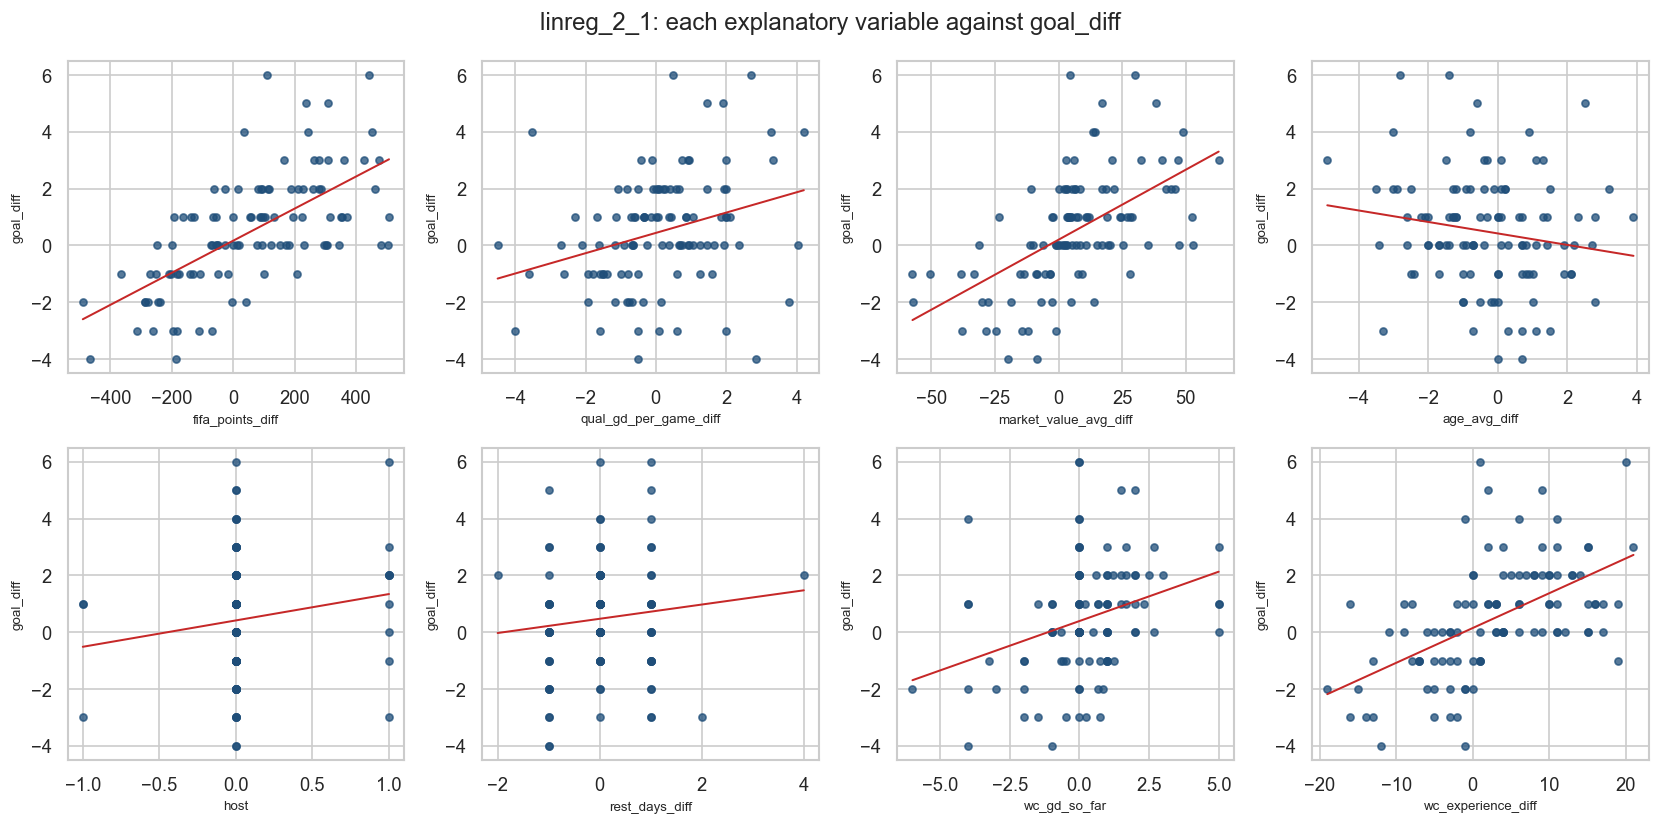

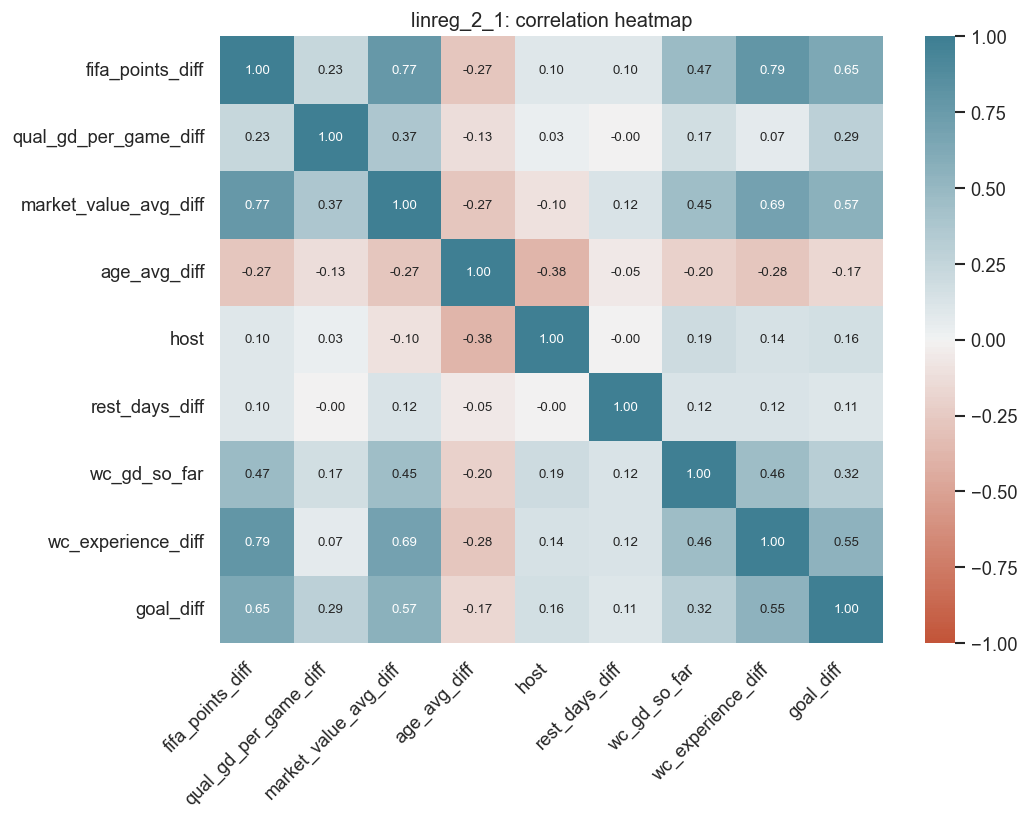

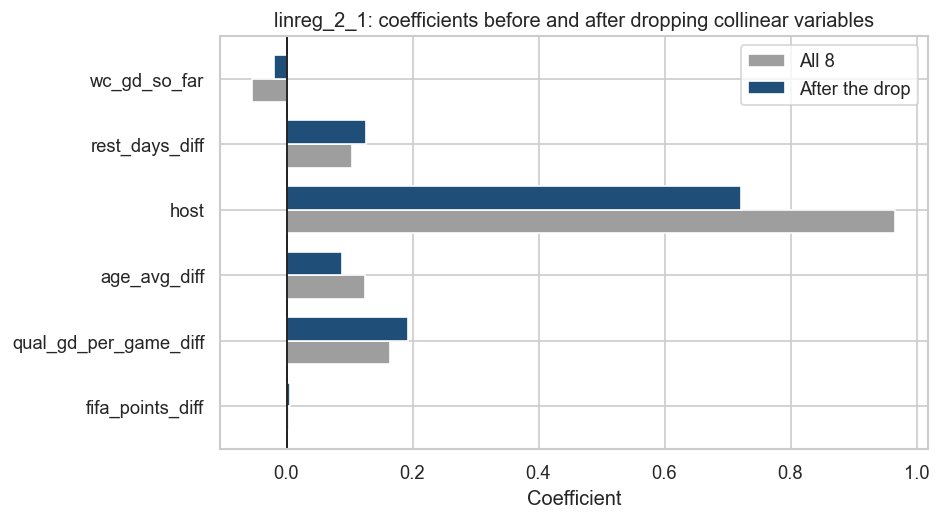

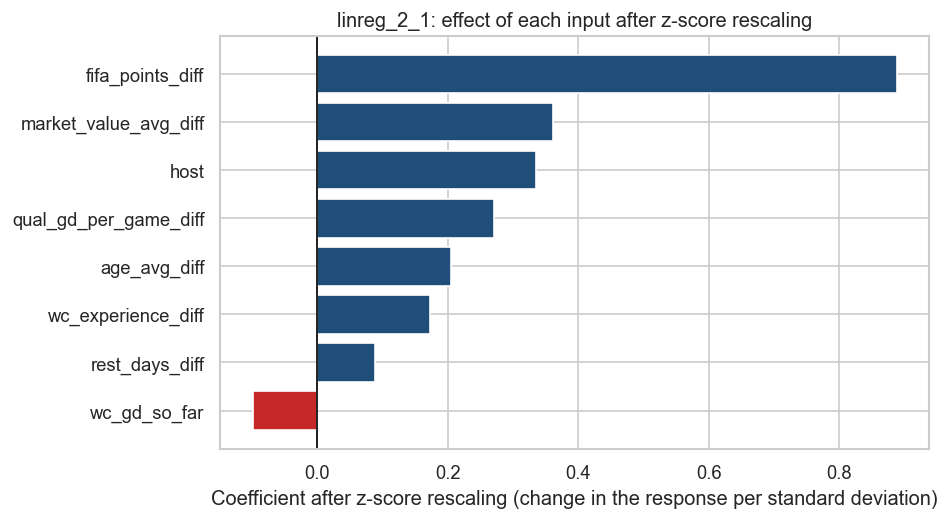

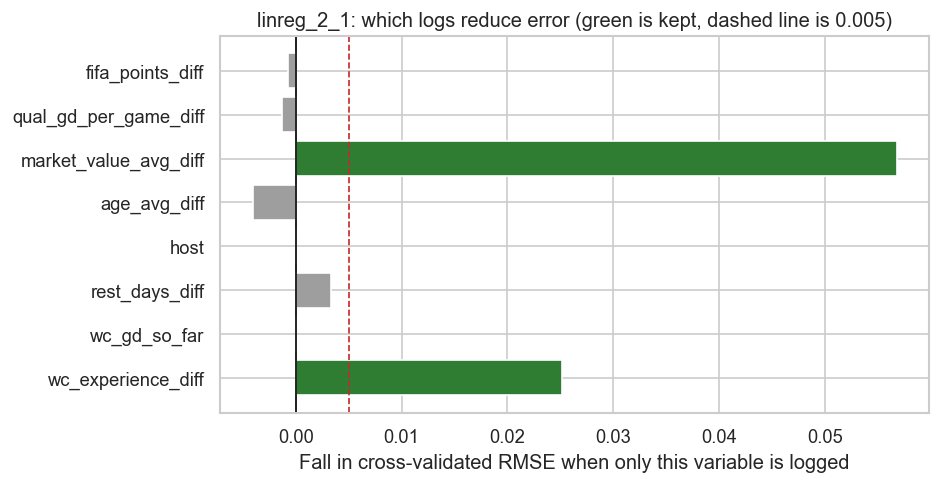

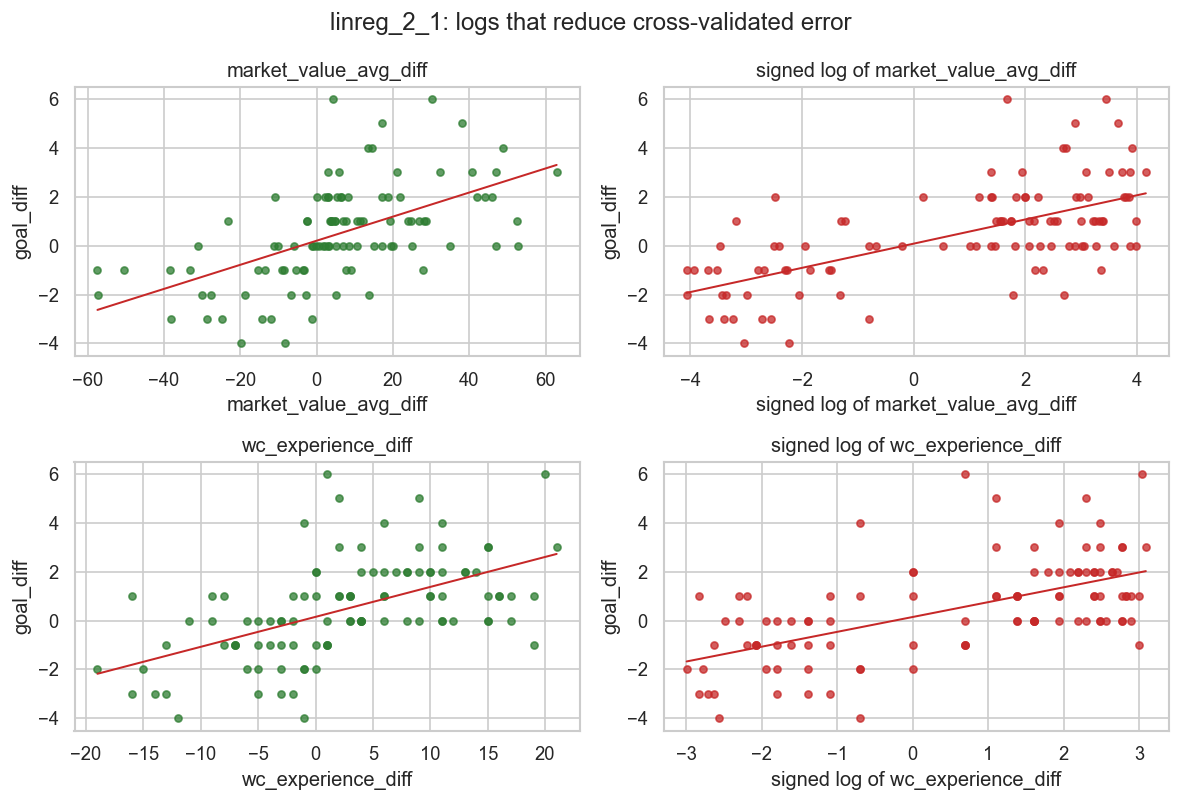

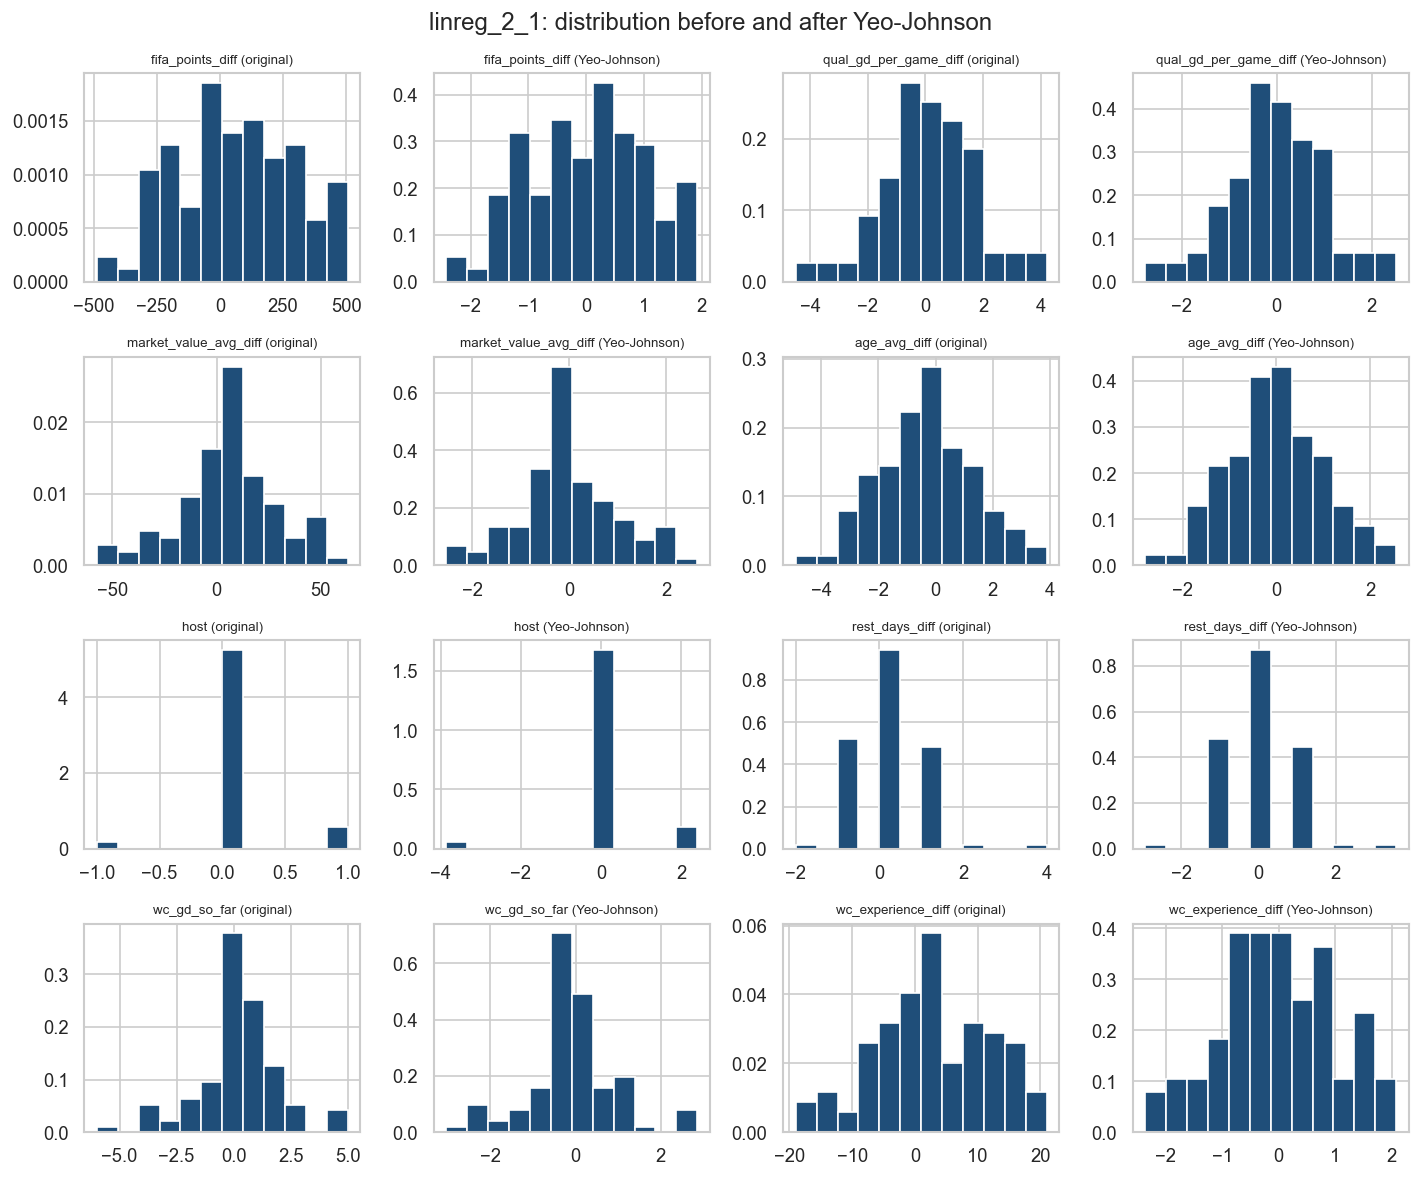

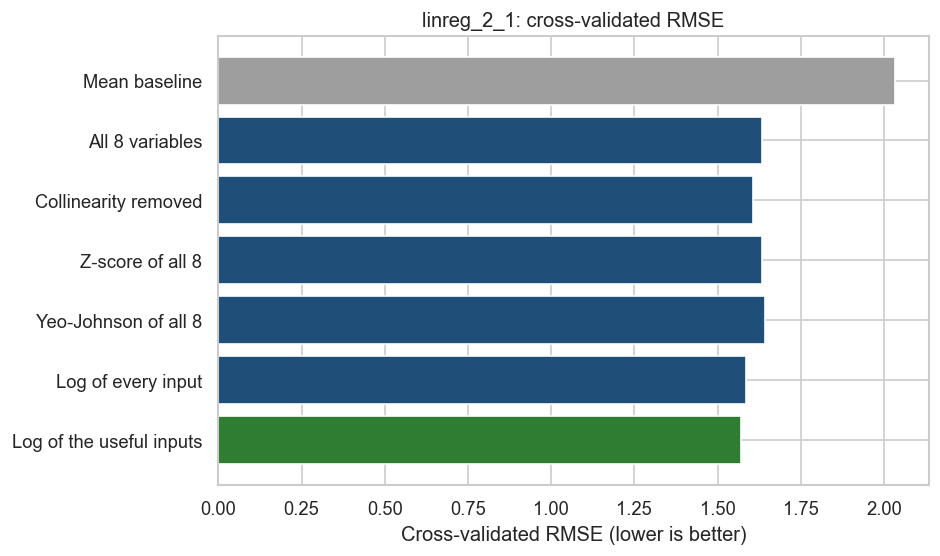

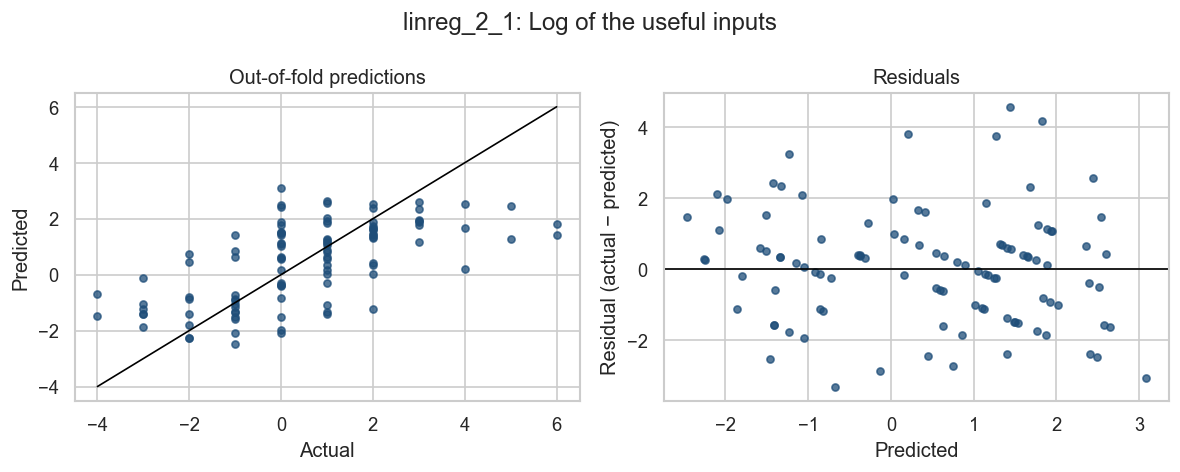

In [5]:
for name in [
    "linreg_2_1_scatters.png",
    "linreg_2_1_heatmap.png",
    "linreg_2_1_collinearity_coef.png",
    "linreg_2_1_zscore_coef.png",
    "linreg_2_1_log_trials.png",
    "linreg_2_1_log_scatter.png",
    "linreg_2_1_yeo_hist.png",
    "linreg_2_1_rmse.png",
    "linreg_2_1_actual_vs_predicted.png",
]:
    display(Image(filename=str(al.CHARTS / name)))

## Linear regression 2.2 — goals scored

Each row is one team in one match. The response is the number of goals that team scored. The inputs are that team's scoring record and the opponent's squad, all known before kickoff.

In [4]:
result_b = al.analyse_task(
    team,
    x2,
    "goals",
    "linreg_2_2",
    {
        "kind": "log1p",
        "column": "qual_gf_per_game",
        "indexes": [
            x2.index(name)
            for name in [
                "qual_gf_per_game",
                "opp_qual_ga_per_game",
                "wc_goals_so_far",
                "opp_wc_ga_so_far",
            ]
        ],
    },
)
al.rounded(result_b["rows"])

,model,MAE,RMSE,NRMSE,R2
0,Mean baseline,1.1176,1.3763,0.1966,-0.0391
1,All 8 variables,1.0689,1.3469,0.1924,-0.0004
2,Z-score of all 8,1.0689,1.3469,0.1924,-0.0004
3,Yeo-Johnson of all 8,1.0866,1.3545,0.1935,-0.0089
4,Log of every input,1.0648,1.3457,0.1922,0.0037
5,Log of the useful inputs,1.0623,1.3398,0.1914,0.0123


In [7]:
print("60/40 split, raw 8 variables")
print("Model   ", {k: round(v, 4) for k, v in result_b["holdout"]["model"].items()})
print("Baseline", {k: round(v, 4) for k, v in result_b["holdout"]["baseline"].items()})
print()
print("Equation fitted on every row (in-sample R-squared", round(result_b["ols_r2"], 4), ")")
print(result_b["equation"])
print()
print("Collinear pairs removed:", len(result_b["dropped"]))
print()
print("Standardised coefficients")
print(result_b["std_coef"][["std_coef"]])

60/40 split, raw 8 variables
Model    {'MAE': 1.0491, 'MSE': 1.8386, 'RMSE': 1.356, 'NRMSE': 0.1937, 'R2': 0.1253}
Baseline {'MAE': 1.159, 'MSE': 2.1097, 'RMSE': 1.4525, 'NRMSE': 0.2075, 'R2': -0.0036}

Equation fitted on every row (in-sample R-squared 0.1309 )
goals = -1.3153 + 0.3905*qual_gf_per_game + 0.3557*opp_qual_ga_per_game - 0.0776*wc_goals_so_far + 0.2192*opp_wc_ga_so_far - 0.0010*foreigners_pct - 0.0017*opp_foreigners_pct + 0.0729*squad_size - 0.0067*opp_squad_size

Collinear pairs removed: 0

Standardised coefficients
                      std_coef
qual_gf_per_game        0.3765
squad_size              0.2602
opp_wc_ga_so_far        0.2408
opp_qual_ga_per_game    0.1569
wc_goals_so_far        -0.0940
opp_foreigners_pct     -0.0475
foreigners_pct         -0.0286
opp_squad_size         -0.0240


The scatters are weak. Qualifying goals per game is the only input with a visible slope. Squad size and the share of foreign-based players are nearly flat. No pair of explanatory variables reaches a correlation of 0.75, so the collinearity check removes nothing.

Z-score rescaling leaves the error unchanged. The largest standardised coefficient is qualifying goals per game. Yeo-Johnson increases the error. Logging qualifying goals per game is the only log that reduces error by more than 0.005. The reduction is small, and cross-validated R-squared stays near zero.

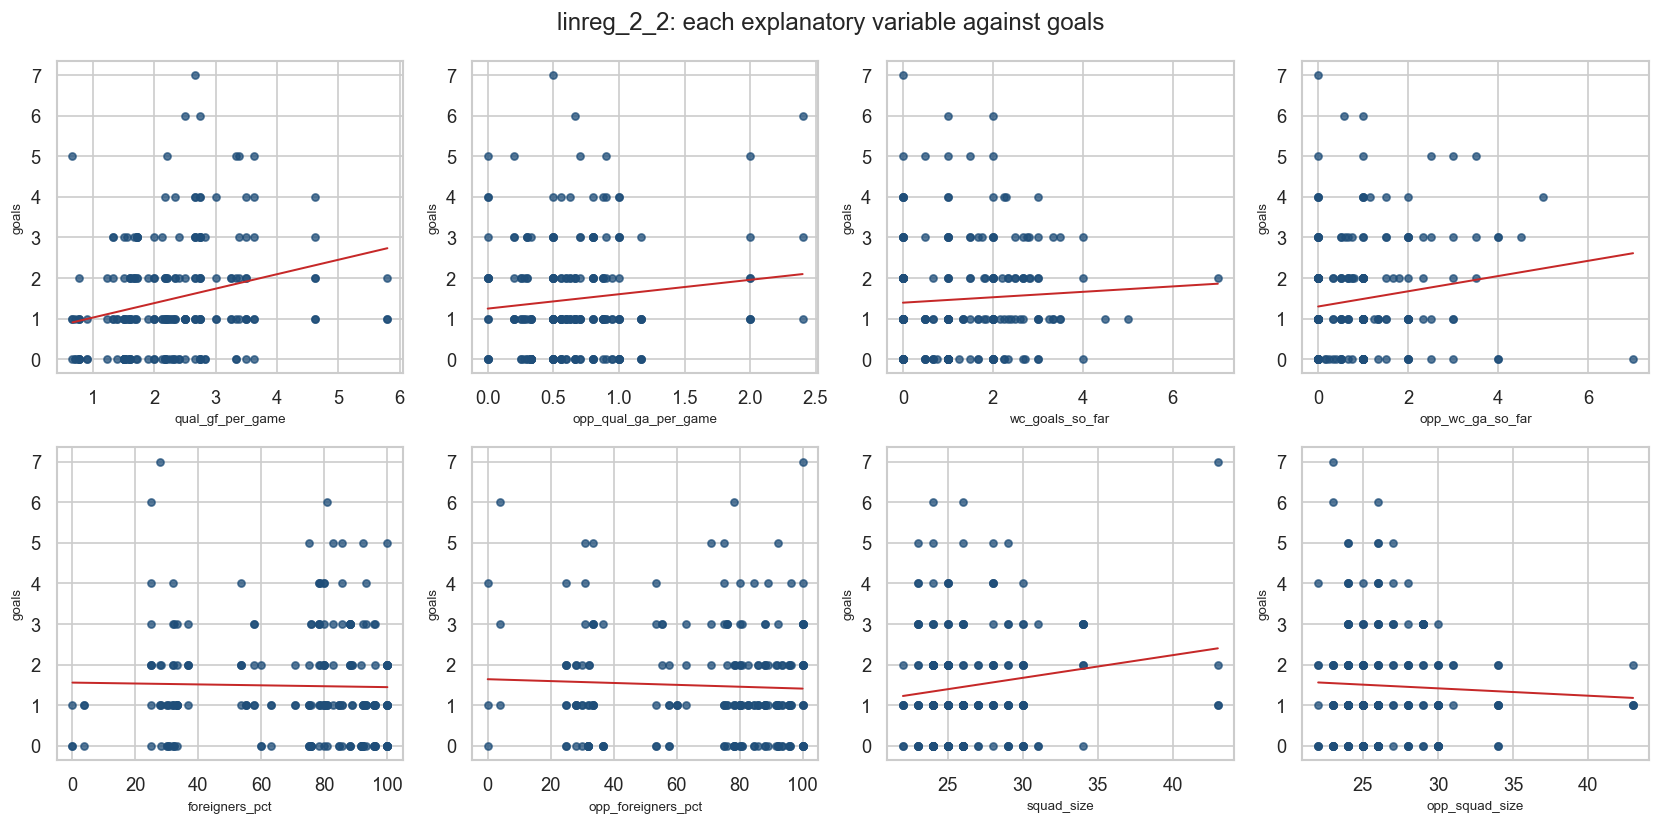

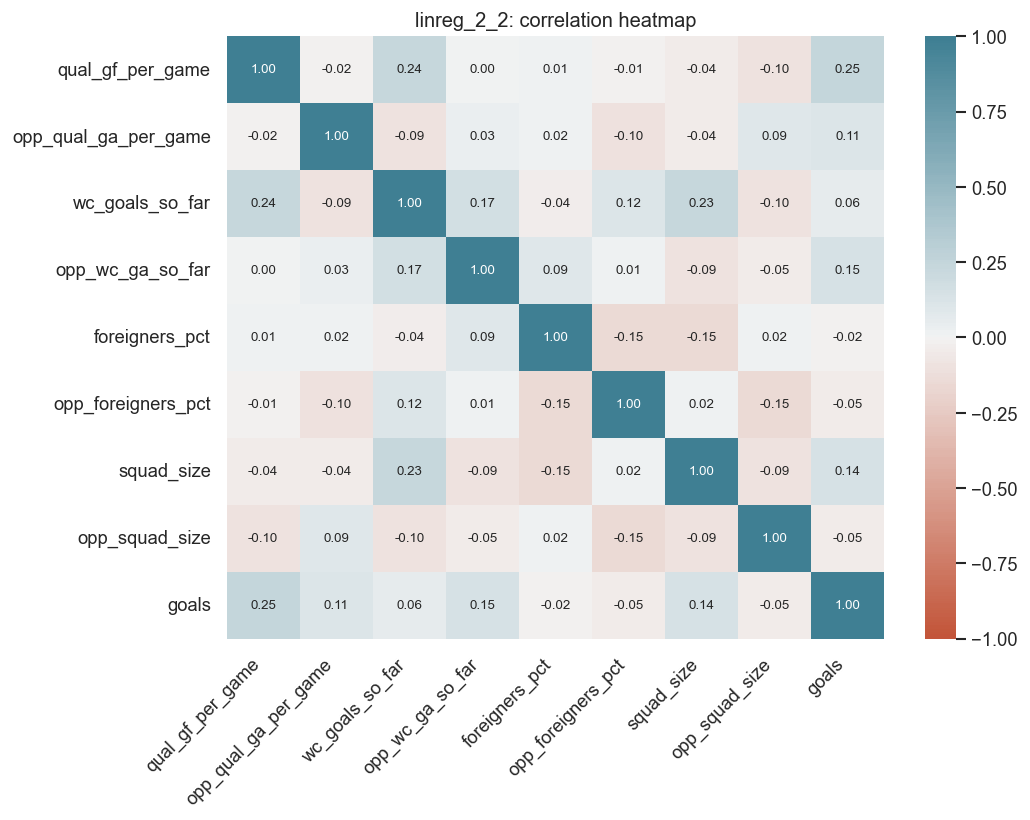

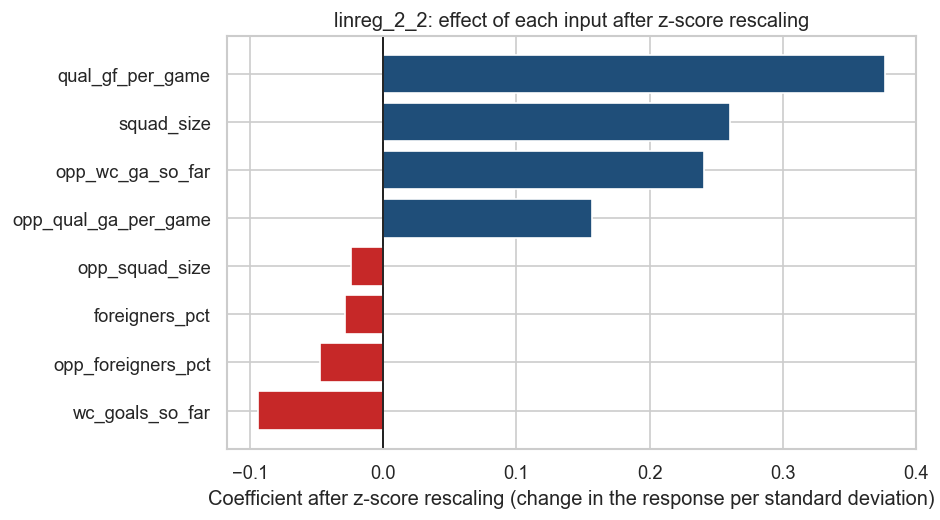

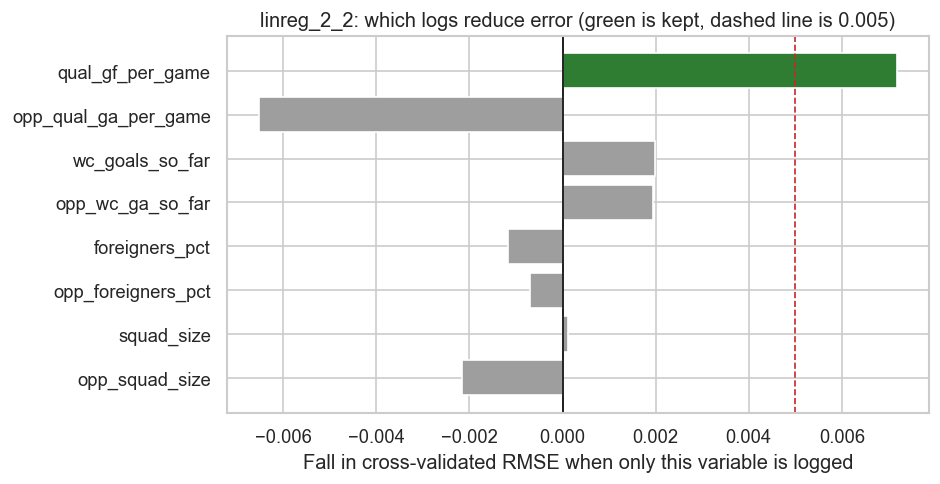

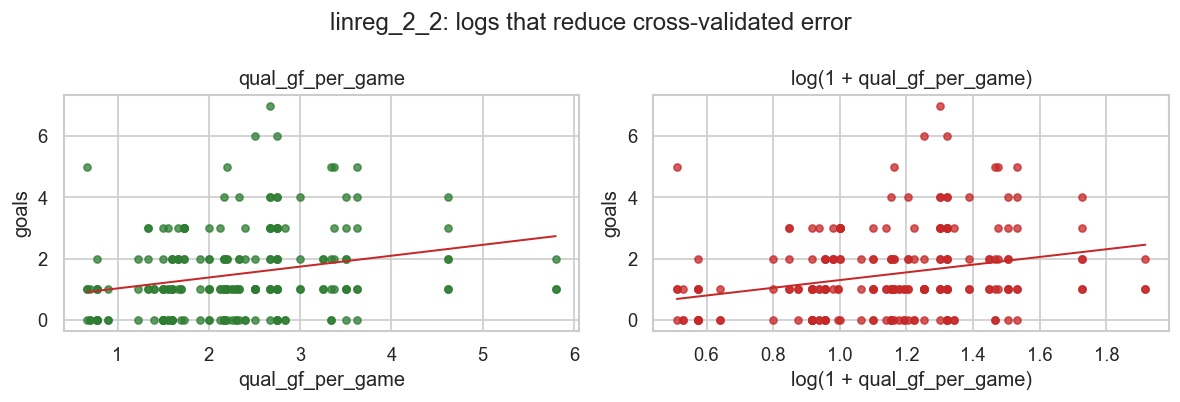

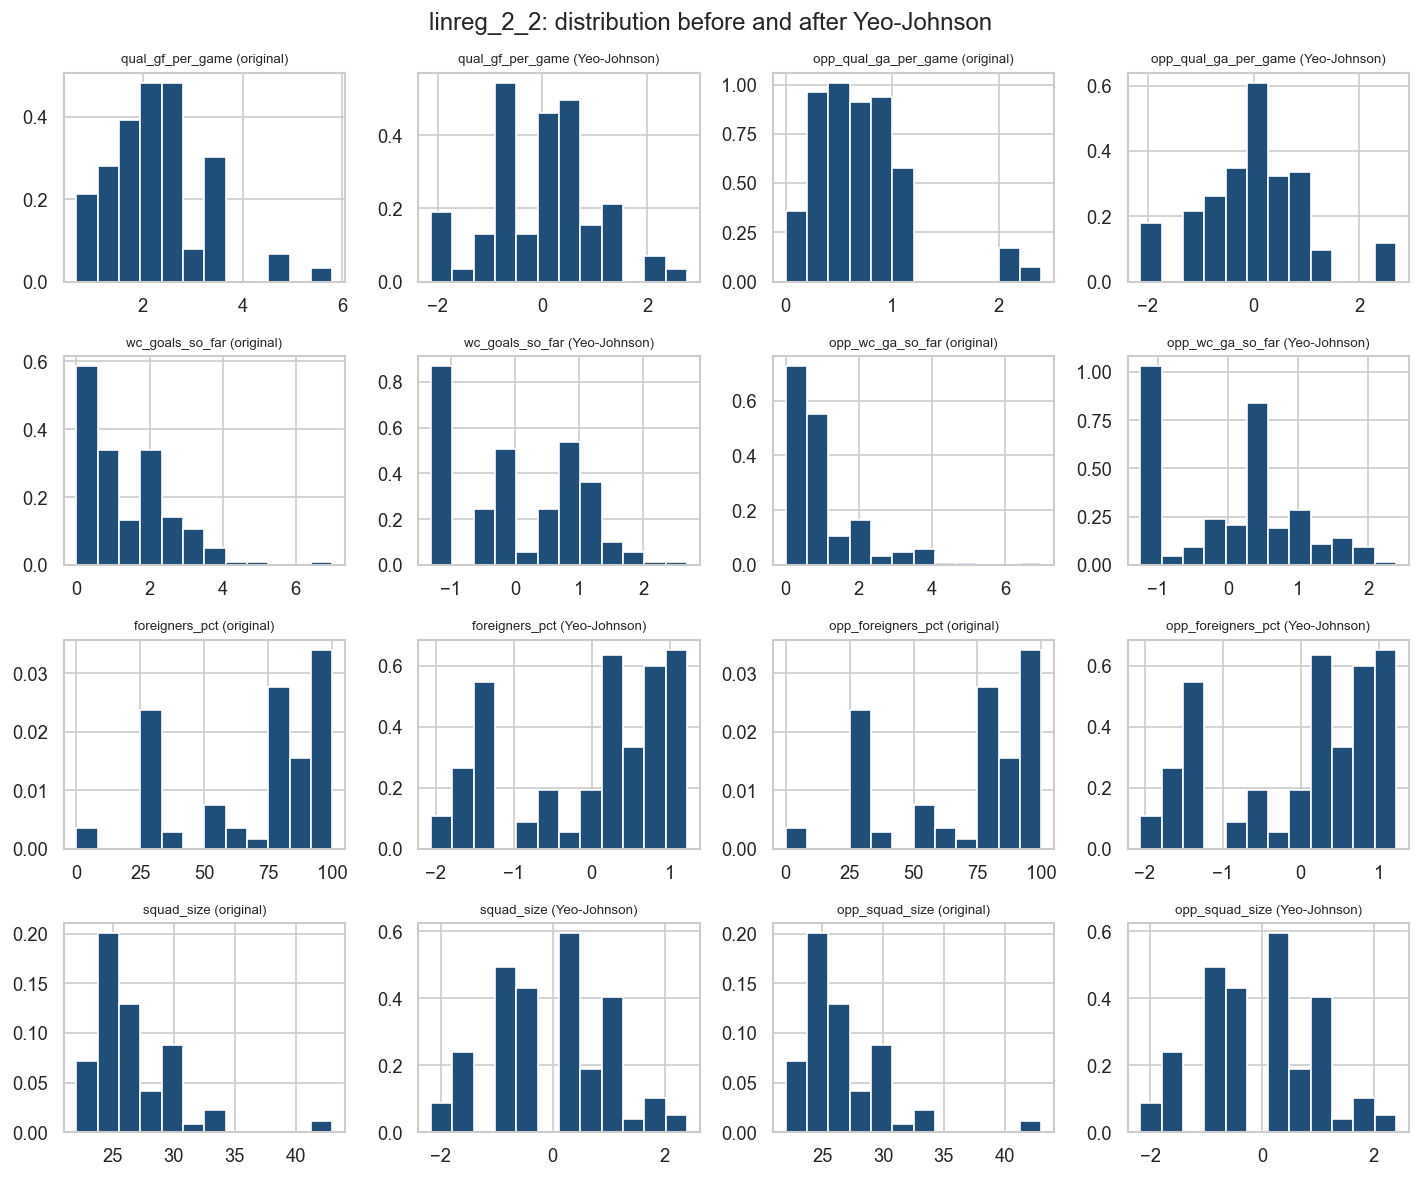

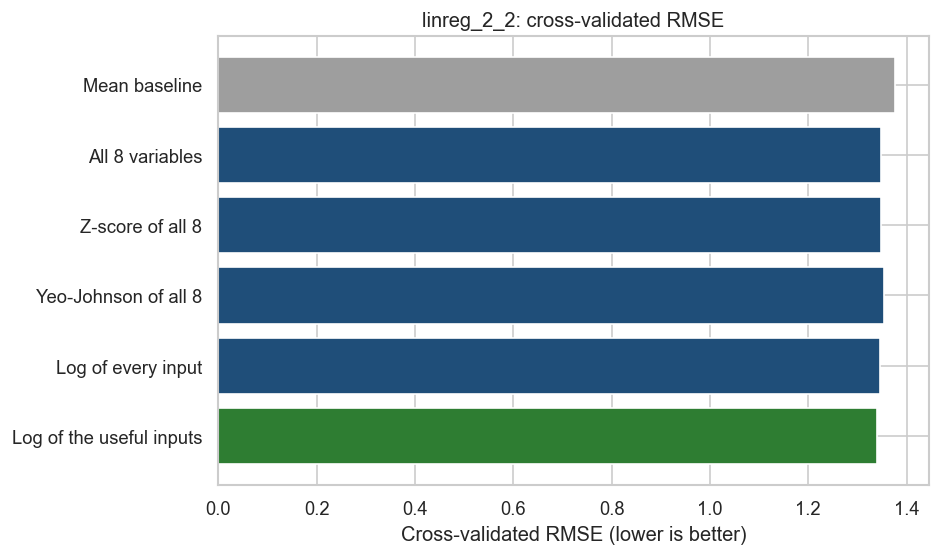

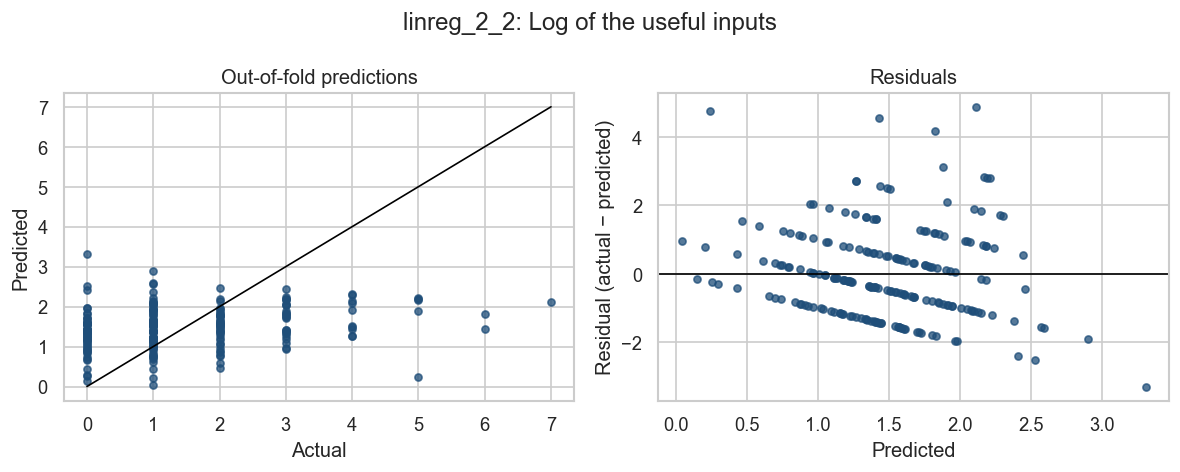

In [ ]:
for name in [
    "linreg_2_2_scatters.png",
    "linreg_2_2_heatmap.png",
    "linreg_2_2_zscore_coef.png",
    "linreg_2_2_log_trials.png",
    "linreg_2_2_log_scatter.png",
    "linreg_2_2_yeo_hist.png",
    "linreg_2_2_rmse.png",
    "linreg_2_2_actual_vs_predicted.png",
]:
    display(Image(filename=str(al.CHARTS / name)))

## Coefficient diagnostics and the matches the line misses

The practical asks for the statsmodels summary, not only the written equation. The standard error, t statistic, and p-value say whether a coefficient is distinguishable from zero on these rows. A small p-value is not the same thing as a lower test error. The cross-validation table above is what decides which model to keep.

The second table names the matches the kept model misses by the most. The residual is actual minus the out-of-fold prediction. A large residual is a result the straight line cannot absorb, usually a blowout.

In [ ]:
def show_diagnostics(result):
    print(result["tag"], "— statsmodels OLS on every row")
    display(result["ols_table"])
    if result["reduced_ols_table"] is not None:
        print("After the collinear variables are removed")
        display(result["reduced_ols_table"])
    readable = result["ols_table"].drop(index="const", errors="ignore")
    clear = readable.index[readable["p_value"] < 0.05].tolist()
    print("Coefficients distinguishable from zero at p < 0.05:", ", ".join(clear) if clear else "none")
    print("Largest misses of the kept model:", result["best_name"])
    display(result["misses"])
    print()

show_diagnostics(result_a)
show_diagnostics(result_b)

linreg_2_1 — statsmodels OLS on every row


,coefficient,std_error,t,p_value
const,0.0918,0.1596,0.5754,0.5664
fifa_points_diff,0.0039,0.0012,3.0906,0.0026
qual_gd_per_game_diff,0.1638,0.1043,1.5704,0.1196
market_value_avg_diff,0.0156,0.0123,1.2673,0.2082
age_avg_diff,0.1244,0.1052,1.1826,0.2399
host,0.9664,0.5197,1.8595,0.0661
rest_days_diff,0.1036,0.1782,0.5813,0.5624
wc_gd_so_far,-0.0541,0.0967,-0.5589,0.5776
wc_experience_diff,0.0193,0.0301,0.6416,0.5227


After the collinear variables are removed


,coefficient,std_error,t,p_value
const,0.1387,0.1575,0.8804,0.3808
fifa_points_diff,0.0054,0.0008,7.0549,0.0000
qual_gd_per_game_diff,0.1924,0.0946,2.0336,0.0447
age_avg_diff,0.0882,0.1031,0.8559,0.3942
host,0.7212,0.4756,1.5163,0.1327
rest_days_diff,0.1269,0.1783,0.7114,0.4786
wc_gd_so_far,-0.0191,0.0948,-0.2019,0.8404


Coefficients distinguishable from zero at p < 0.05: fifa_points_diff
Largest misses of the kept model: Log of the useful inputs


,row,actual,predicted,residual
24,M025_Canada_Qatar,6.0000,1.4340,4.5660
8,M009_Germany_Curacao,6.0000,1.8250,4.1750
11,M012_Sweden_Tunisia,4.0000,0.2030,3.7970
61,M062_Senegal_Iraq,5.0000,1.2640,3.7360
35,M036_Tunisia_Japan,-4.0000,-0.6820,-3.3180
7,M008_Australia_Turkey,2.0000,-1.2320,3.2320



linreg_2_2 — statsmodels OLS on every row


,coefficient,std_error,t,p_value
const,-1.3153,1.2134,-1.0839,0.2797
qual_gf_per_game,0.3905,0.0993,3.9321,0.0001
opp_qual_ga_per_game,0.3557,0.2109,1.6868,0.0932
wc_goals_so_far,-0.0776,0.0833,-0.9323,0.3523
opp_wc_ga_so_far,0.2192,0.0861,2.5448,0.0117
foreigners_pct,-0.0010,0.0035,-0.3038,0.7616
opp_foreigners_pct,-0.0017,0.0035,-0.5000,0.6177
squad_size,0.0729,0.0272,2.6759,0.0081
opp_squad_size,-0.0067,0.0264,-0.2551,0.7989


Coefficients distinguishable from zero at p < 0.05: qual_gf_per_game, opp_wc_ga_so_far, squad_size
Largest misses of the kept model: Log of the useful inputs


,row,actual,predicted,residual
16,M009_Germany_Curacao_Germany,7.0000,2.1090,4.8910
22,M012_Sweden_Tunisia_Sweden,5.0000,0.2400,4.7600
205,M103_France_England_England,6.0000,1.4330,4.5670
48,M025_Canada_Qatar_Canada,6.0000,1.8220,4.1780
62,M032_Turkey_Paraguay_Turkey,0.0000,3.3040,-3.3040
122,M062_Senegal_Iraq_Senegal,5.0000,1.8830,3.1170


## Comparison and recommendation

In [ ]:
comparison = pd.concat(
    [
        al.rounded(result_a["rows"]).assign(task="2.1 goal difference"),
        al.rounded(result_b["rows"]).assign(task="2.2 goals scored"),
    ],
    ignore_index=True,
)
for column in ("MAE", "RMSE", "NRMSE", "R2"):
    comparison[column] = comparison[column].round(4)
comparison["kept"] = comparison["model"].eq("Log of the useful inputs")
text = al.recommendation_text(result_a, result_b)
print(comparison.to_string(index=False))
print()
print(text)

                   model    MAE   RMSE  NRMSE      R2                task
           Mean baseline 1.5885 2.0330 0.2033 -0.1102 2.1 goal difference
         All 8 variables 1.2971 1.6345 0.1634  0.2703 2.1 goal difference
    Collinearity removed 1.2940 1.6074 0.1607  0.2987 2.1 goal difference
        Z-score of all 8 1.2971 1.6345 0.1634  0.2703 2.1 goal difference
    Yeo-Johnson of all 8 1.3050 1.6430 0.1643  0.2636 2.1 goal difference
      Log of every input 1.2448 1.5850 0.1585  0.3067 2.1 goal difference
Log of the useful inputs 1.2382 1.5691 0.1569  0.3244 2.1 goal difference
           Mean baseline 1.1176 1.3763 0.1966 -0.0391    2.2 goals scored
         All 8 variables 1.0689 1.3469 0.1924 -0.0004    2.2 goals scored
        Z-score of all 8 1.0689 1.3469 0.1924 -0.0004    2.2 goals scored
    Yeo-Johnson of all 8 1.0866 1.3545 0.1935 -0.0089    2.2 goals scored
      Log of every input 1.0648 1.3457 0.1922  0.0037    2.2 goals scored
Log of the useful inputs 1.0623 1.3398

The report can point to `scripts/analyse_linreg.py` for the code and to this notebook for the figures. Use the cross-validated RMSE in the table above, not the in-sample R-squared.

**2.1.** Use the signed log of market value and World Cup experience, and leave the other six gaps unchanged. That model has the lowest cross-validated error.

**2.2.** Use `log(1 + qualifying goals per game)`, and leave the other seven inputs unchanged. This model is only a little better than the baseline.